In [1]:
from model import *
from copy import deepcopy

In [2]:
config = GPTConfig()

In [3]:
model = Block(config).to(torch.float64)
model_64 = deepcopy(model).to(torch.float64)

In [4]:
X = 10*torch.randn((16, 1024, config.n_embd), dtype=torch.float64)

In [5]:
model = model.to('cuda')
X = X.to('cuda')
model.eval()
with torch.no_grad():
    output = model(X)[0]

In [6]:
def rerror(a, b):
    mask = a.isnan() | b.isnan() | a.isinf() | b.isinf()
    a = a.to('cpu').to(torch.float64)
    b = b.to('cpu').to(torch.float64)
    mask = mask.to('cpu')
    a[mask] = 0
    b[mask] = 0
    f_err = torch.norm(a - b) / torch.norm(a)
    one_err = torch.norm(a - b, 1) / torch.norm(a, 1)
    return f_err.item(), one_err.item()

In [7]:
model_16 = model.to(torch.float16)
X_16 = X.to(torch.float16)
model_16.eval()
with torch.no_grad():
    output_16 = model_16(X_16)[0]

In [8]:
f, one = rerror(X, X_16)
print(f"Input relative error: {f:.2e}, {one:.2e}, (f-norm, 1-norm)")
f_, one_ = rerror(output, output_16)
print(f"Output relative error: {f_:.2e}, {one_:.2e}, (f-norm, 1-norm)")
cond_f, cond_one = f_ / f, one_ / one
print(f"Relative condition number: {cond_f:.2e}, {cond_one:.2e}, (f-norm, 1-norm)")

Input relative error: 2.07e-04, 1.76e-04, (f-norm, 1-norm)
Output relative error: 3.59e-04, 2.88e-04, (f-norm, 1-norm)
Relative condition number: 1.73e+00, 1.63e+00, (f-norm, 1-norm)


In [9]:
model_16.eval()
for i in range(1):
    Delta = 1e-2 * torch.randn_like(X_16, dtype=torch.float16)
    X_Delta = X_16 + Delta
    with torch.no_grad():
        output_Delta = model_16(X_Delta)[0]
    abs_cond_f = torch.norm(output - output_Delta) / torch.norm(Delta)
    rel_cond_f = abs_cond_f / torch.norm(output) * torch.norm(X)
    abs_cond_one = torch.norm(output - output_Delta, 1) / torch.norm(Delta, 1)
    rel_cond_one = abs_cond_one / torch.norm(output, 1) * torch.norm(X, 1)
    print(rel_cond_f.item(), rel_cond_one.item())

1.0818543360888022 0.0


In [10]:
model_64 = model_64.to('cuda')
model_64.eval()
for i in range(10):
    Delta = 1e-3 * torch.randn_like(X)
    X_Delta = X + Delta
    with torch.no_grad():
        output_Delta = model_64(X_Delta)[0]
    abs_cond_f = torch.norm(output - output_Delta) / torch.norm(Delta)
    rel_cond_f = abs_cond_f / torch.norm(output) * torch.norm(X)
    abs_cond_one = torch.norm(output - output_Delta, 1) / torch.norm(Delta, 1)
    rel_cond_one = abs_cond_one / torch.norm(output, 1) * torch.norm(X, 1)
    print(rel_cond_f.item(), rel_cond_one.item())

1.000012290829827 1.0000074673510724
1.000010323232094 1.0000154028384836
1.0000261217046114 1.00003496329639
1.00001468721825 1.0000163455034852
1.0000061779585625 1.0000145219515246
1.0000190670940636 1.0000278210527556
1.0000233314747211 1.0000338864953577
1.0000114331034944 1.0000262822169714
1.0000182644133084 1.0000192639855001
1.000017469101093 1.0000204015561922


In [11]:
rerr_f = []
rerr_one = []

In [12]:
cond_f = []
cond_one = []

In [13]:
cond_fp64_f = []
cond_fp64_one = []

In [14]:
Transformer = torch.nn.ModuleList([Block(config) for _ in range(48)]).to(torch.float64).to('cuda')
Transformer_64 = deepcopy(Transformer).to(torch.float64).to('cuda')
Transformer_16 = deepcopy(Transformer).to(torch.float16).to('cuda')
X = torch.rand((16, 1024, config.n_embd), dtype=torch.float64).to('cuda')
X_16 = deepcopy(X).to(torch.float16)
f, one = rerror(X, X_16)

In [15]:
rerr_f.append(f)
rerr_one.append(one)

In [16]:
Transformer.eval()
Transformer_64.eval()
Transformer_16.eval()
with torch.no_grad():
    for i in range(len(Transformer)):
        Y = Transformer[i](X)[0]
        Y_16 = Transformer_16[i](X_16)[0]
        f, one = rerror(Y, Y_16)
        rerr_f.append(f)
        rerr_one.append(one)
        Delta = 1e-7 * torch.randn_like(X)
        X_Delta = X + Delta
        Y_Delta = Transformer[i](X_Delta)[0]
        abs_cond_f = torch.norm(Y - Y_Delta) / torch.norm(Delta)
        rel_cond_f = abs_cond_f / torch.norm(Y) * torch.norm(X)
        abs_cond_one = torch.norm(Y - Y_Delta, 1) / torch.norm(Delta, 1)
        rel_cond_one = abs_cond_one / torch.norm(Y, 1) * torch.norm(X, 1)
        cond_fp64_f.append(rel_cond_f.item())
        cond_fp64_one.append(rel_cond_one.item())
        Delta_16 = 1e-2 * torch.randn_like(X_16)
        X_Delta_16 = X_16 + Delta_16
        Y_Delta_16 = Transformer_16[i](X_Delta_16)[0]
        abs_cond_f = torch.norm(Y - Y_Delta_16) / torch.norm(Delta_16)
        rel_cond_f = abs_cond_f / torch.norm(Y) * torch.norm(X)
        abs_cond_one = torch.norm(Y - Y_Delta_16, 1) / torch.norm(Delta_16, 1)
        rel_cond_one = abs_cond_one / torch.norm(Y, 1) * torch.norm(X, 1)
        cond_f.append(rel_cond_f.item())
        cond_one.append(rel_cond_one.item())
        X = Y
        X_16 = Y_16



In [17]:
for i in range(len(cond_f)):
    print(f"Layer {i}: {cond_f[i]:.2e}, {cond_fp64_f[i]:.2e}")

Layer 0: 1.16e+00, 1.16e+00
Layer 1: 1.09e+00, 1.09e+00
Layer 2: 1.04e+00, 1.04e+00
Layer 3: 1.03e+00, 1.02e+00
Layer 4: 1.01e+00, 1.01e+00
Layer 5: 1.00e+00, 9.97e-01
Layer 6: 9.87e-01, 9.83e-01
Layer 7: 9.80e-01, 9.75e-01
Layer 8: 9.80e-01, 9.74e-01
Layer 9: 9.88e-01, 9.81e-01
Layer 10: 9.92e-01, 9.84e-01
Layer 11: 9.81e-01, 9.72e-01
Layer 12: 9.95e-01, 9.84e-01
Layer 13: 9.91e-01, 9.79e-01
Layer 14: 9.99e-01, 9.85e-01
Layer 15: 9.89e-01, 9.74e-01
Layer 16: 9.98e-01, 9.82e-01
Layer 17: 9.99e-01, 9.81e-01
Layer 18: 1.01e+00, 9.86e-01
Layer 19: 1.01e+00, 9.85e-01
Layer 20: 1.01e+00, 9.85e-01
Layer 21: 1.01e+00, 9.87e-01
Layer 22: 1.02e+00, 9.89e-01
Layer 23: 1.00e+00, 9.73e-01
Layer 24: 1.02e+00, 9.87e-01
Layer 25: 1.02e+00, 9.82e-01
Layer 26: 1.02e+00, 9.85e-01
Layer 27: 1.03e+00, 9.91e-01
Layer 28: 1.02e+00, 9.80e-01
Layer 29: 1.03e+00, 9.87e-01
Layer 30: 1.03e+00, 9.84e-01
Layer 31: 1.04e+00, 9.92e-01
Layer 32: 1.05e+00, 9.95e-01
Layer 33: 1.04e+00, 9.89e-01
Layer 34: 1.05e+00, 9.89

In [18]:
predict_r = [9.8e-4]
for cond in cond_f:
    predict_r.append(predict_r[-1] * cond)
m = 0
for i in range(len(predict_r)):
    if predict_r[i] > m:
        m = predict_r[i]
    predict_r[i] = max(predict_r[i], m)

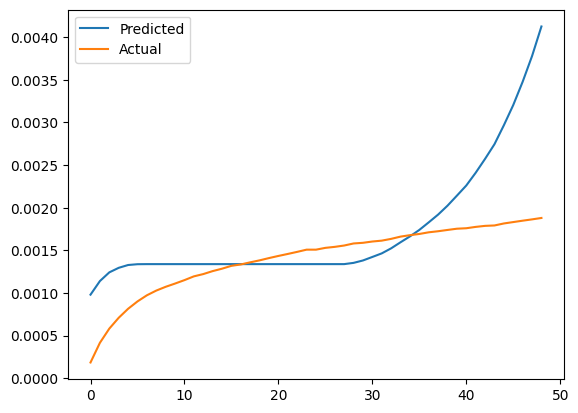

In [19]:
import numpy as np
import matplotlib.pyplot as plt
plt.plot(np.arange(len(Transformer)+1), predict_r, label='Predicted')
plt.plot(np.arange(len(Transformer)+1), rerr_f, label='Actual')
plt.legend()

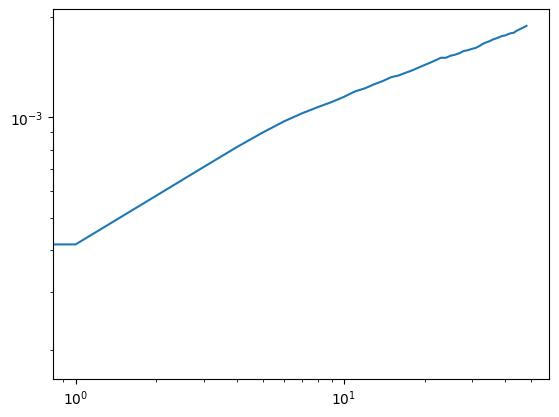

In [20]:
plt.plot(np.arange(len(Transformer)+1), rerr_f, label='Actual')
plt.xscale('log')
plt.yscale('log')

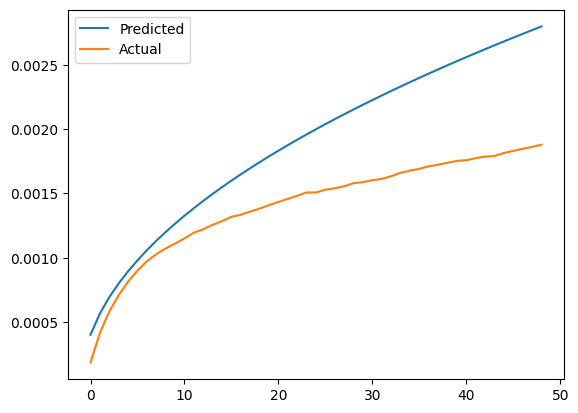

In [27]:
plog = (1e-3 * 0.4*np.sqrt(np.arange(1, len(Transformer)+2))).tolist()
plt.plot(np.arange(len(Transformer)+1), plog, label='Predicted')
plt.plot(np.arange(len(Transformer)+1), rerr_f, label='Actual')
# plt.xscale('log')
# plt.yscale('log')
plt.legend()

In [112]:
0.33/np.log(2)

0.47608936349335795